# 02 – Strats, valuation & scenarios
**Greek NPL Portfolio Due Diligence & Pricing** · *Synthetic data for practice only.*

Question: **how much would an investor pay for this portfolio (EUR and % of GBV), and which parts of it are worth the most?**

In [1]:
import pandas as pd, numpy as np, sqlite3
import matplotlib.pyplot as plt
pd.set_option('display.float_format', '{:,.2f}'.format)
loans = pd.read_csv('../data/npl_loan_tape_clean.csv')
print(loans.shape, '| GBV EUR m:', round(loans['gross_book_value'].sum()/1e6, 1))

(20000, 24) | GBV EUR m: 2380.8


## 1. Strats with SQL (SQLite)
The queries are in `sql/strats.sql`; here they run on an in-memory SQLite copy of the clean tape.

In [2]:
con = sqlite3.connect(':memory:')
loans.to_sql('loans', con, index=False)
queries = [q.strip() for q in open('../sql/strats.sql', encoding='utf-8').read().split(';') if 'SELECT' in q]
results = [pd.read_sql(q, con) for q in queries]
results[0]

,loans,borrowers,gbv_eur_m,avg_gbv_eur,secured_pct_gbv
0,20000,11227,"2,380.80","119,042.00",73.60


In [3]:
results[1]  # by segment

,segment,loans,gbv_eur_m,pct_gbv,pct_loans_secured
0,Corporate,595,896.50,37.70,72.90
1,SME,3367,728.40,30.60,59.90
2,Retail Mortgage,7609,665.90,28.00,97.00
3,Consumer,5370,73.00,3.10,4.70
4,Credit Card,3059,17.10,0.70,0.00


In [4]:
results[2]  # by legal status

,legal_status,loans,gbv_eur_m,pct_gbv
0,Denounced,10357,"1,124.10",47.20
1,Amicable,4015,470.70,19.80
2,Auction,2499,448.00,18.80
3,Bankruptcy/Insolvency,1977,237.90,10.00
4,Law 3869/2010,1152,100.10,4.20


In [5]:
results[3]  # by LTV bucket (secured, valued)

,ltv_bucket,loans,gbv_eur_m,omv_eur_m
0,1) <80%,2404,419.70,700.40
1,2) 80-100%,1802,325.60,362.60
2,3) 100-120%,1607,255.70,233.00
3,4) 120-150%,1843,313.30,235.90
4,5) >150%,2404,435.30,229.60


In [6]:
results[4]  # top 10 regions

,region,loans,gbv_eur_m
0,Αττική,7113,888.80
1,Κεντρική Μακεδονία,3414,443.60
2,Θεσσαλία,1146,140.10
3,Πελοπόννησος,1060,128.70
4,Δυτική Ελλάδα,1193,127.80
5,Κρήτη,1188,127.00
6,Στερεά Ελλάδα,1009,117.30
7,Ανατολική Μακεδονία και Θράκη,1023,111.60
8,Δυτική Μακεδονία,584,69.50
9,Ήπειρος,618,65.30


In [7]:
results[5]  # top-20 borrower concentration

,top20_pct_gbv
0,5.80


## 2. Valuation assumptions (same as `excel/NPL_Portfolio_Valuation_Model.xlsx`)

In [8]:
HAIRCUT = {'Residential': 0.30, 'Commercial': 0.40, 'Land': 0.55}
LIEN = {1: 1.0, 2: 0.5, 3: 0.2}
UNSECURED_REC = {'Retail Mortgage': 0.03, 'Consumer': 0.04, 'Credit Card': 0.03, 'SME': 0.06, 'Corporate': 0.08}
YEARS = {'Amicable': 2, 'Denounced': 3, 'Auction': 4, 'Law 3869/2010': 5, 'Bankruptcy/Insolvency': 6}
SERVICING_FEE, LEGAL_COST, SHORTFALL_FACTOR = 0.08, 0.03, 0.5
RATES = {'Low (10%)': 0.10, 'Base (12%)': 0.12, 'High (15%)': 0.15}

## 3. Loan-level expected collections and NPV
- Secured with valid OMV: collateral recovery = min(GBV, OMV × (1 − haircut) × lien factor) + shortfall × unsecured rate × 0.5
- Unsecured (or no valid OMV): GBV × unsecured rate
- Net = gross × (1 − servicing fee) − legal cost × collateral recovery
- NPV = net / (1 + r)^years (single bullet cash flow – a simplification)

In [9]:
def value(df, r=0.12, haircut_shift=0.0):
    d = df.copy()
    has_coll = (d['secured'] == 1) & (d['omv_missing'] == 0)
    hc = (d['collateral_type'].map(HAIRCUT).fillna(0) + haircut_shift).clip(0, 1)
    coll_rec = np.where(has_coll, np.minimum(d['gross_book_value'],
                        d['collateral_value_omv'] * (1 - hc) * d['lien_rank'].map(LIEN)), 0.0)
    rate = d['segment'].map(UNSECURED_REC)
    shortfall = d['gross_book_value'] - coll_rec
    d['collateral_recovery'] = coll_rec
    d['gross_collections'] = np.where(has_coll, coll_rec + shortfall * rate * SHORTFALL_FACTOR,
                                      d['gross_book_value'] * rate)
    d['net_collections'] = d['gross_collections'] * (1 - SERVICING_FEE) - LEGAL_COST * coll_rec
    d['years'] = d['legal_status'].map(YEARS)
    d['npv'] = d['net_collections'] / (1 + r) ** d['years']
    return d

base = value(loans)
tot = base[['gross_book_value', 'gross_collections', 'net_collections', 'npv']].sum()
print((tot / 1e6).round(1).to_string())
print('Price % GBV (base, r = 12%):', round(100 * tot['npv'] / tot['gross_book_value'], 1))

gross_book_value    2,380.80
gross_collections     989.30
net_collections       882.40
npv                   602.20
Price % GBV (base, r = 12%): 25.3


## 4. Price by segment and by legal status (base case)

In [10]:
def price_table(d, by):
    g = d.groupby(by)[['gross_book_value', 'net_collections', 'npv']].sum()
    g['price_pct_gbv'] = 100 * g['npv'] / g['gross_book_value']
    g['share_of_price_pct'] = 100 * g['npv'] / g['npv'].sum()
    g[['gross_book_value', 'net_collections', 'npv']] /= 1e6
    return g.sort_values('npv', ascending=False).round(1)
by_seg = price_table(base, 'segment'); by_seg

,gross_book_value,net_collections,npv,price_pct_gbv,share_of_price_pct
segment,,,,,
Retail Mortgage,665.90,335.10,223.30,33.50,37.10
Corporate,896.50,320.90,221.70,24.70,36.80
SME,728.40,221.80,154.00,21.10,25.60
Consumer,73.00,4.10,2.90,4.00,0.50
Credit Card,17.10,0.50,0.30,2.00,0.10


In [11]:
price_table(base, 'legal_status')

,gross_book_value,net_collections,npv,price_pct_gbv,share_of_price_pct
legal_status,,,,,
Denounced,"1,124.10",353.10,251.40,22.40,41.70
Amicable,470.70,179.50,143.10,30.40,23.80
Auction,448.00,212.70,135.20,30.20,22.40
Bankruptcy/Insolvency,237.90,85.40,43.30,18.20,7.20
Law 3869/2010,100.10,51.60,29.30,29.30,4.90


In [12]:
price_table(base, 'secured')

,gross_book_value,net_collections,npv,price_pct_gbv,share_of_price_pct
secured,,,,,
1,"1,753.00",845.60,576.30,32.90,95.70
0,627.90,36.80,25.90,4.10,4.30


## 5. Scenarios: discount rate × haircut

In [13]:
rows = []
for shift in [-0.10, 0.0, 0.10]:
    row = {}
    for name, r in RATES.items():
        d = value(loans, r=r, haircut_shift=shift)
        row[name] = 100 * d['npv'].sum() / d['gross_book_value'].sum()
    rows.append(pd.Series(row, name=f'Haircut {shift*100:+.0f}pp' if shift else 'Base haircut'))
scen = pd.DataFrame(rows).round(1); scen

,Low (10%),Base (12%),High (15%)
Haircut -10pp,29.80,28.10,25.80
Base haircut,26.80,25.30,23.20
Haircut +10pp,23.50,22.10,20.30


In [14]:
npv_eur = pd.DataFrame({name: [value(loans, r=r, haircut_shift=s)['npv'].sum()/1e6 for s in [-0.10, 0, 0.10]]
                        for name, r in RATES.items()}, index=['Haircut -10pp', 'Haircut base', 'Haircut +10pp']).round(1)
npv_eur  # EUR m

,Low (10%),Base (12%),High (15%)
Haircut -10pp,710.50,669.40,613.70
Haircut base,639.20,602.20,552.10
Haircut +10pp,559.60,527.20,483.30


## 6. Charts

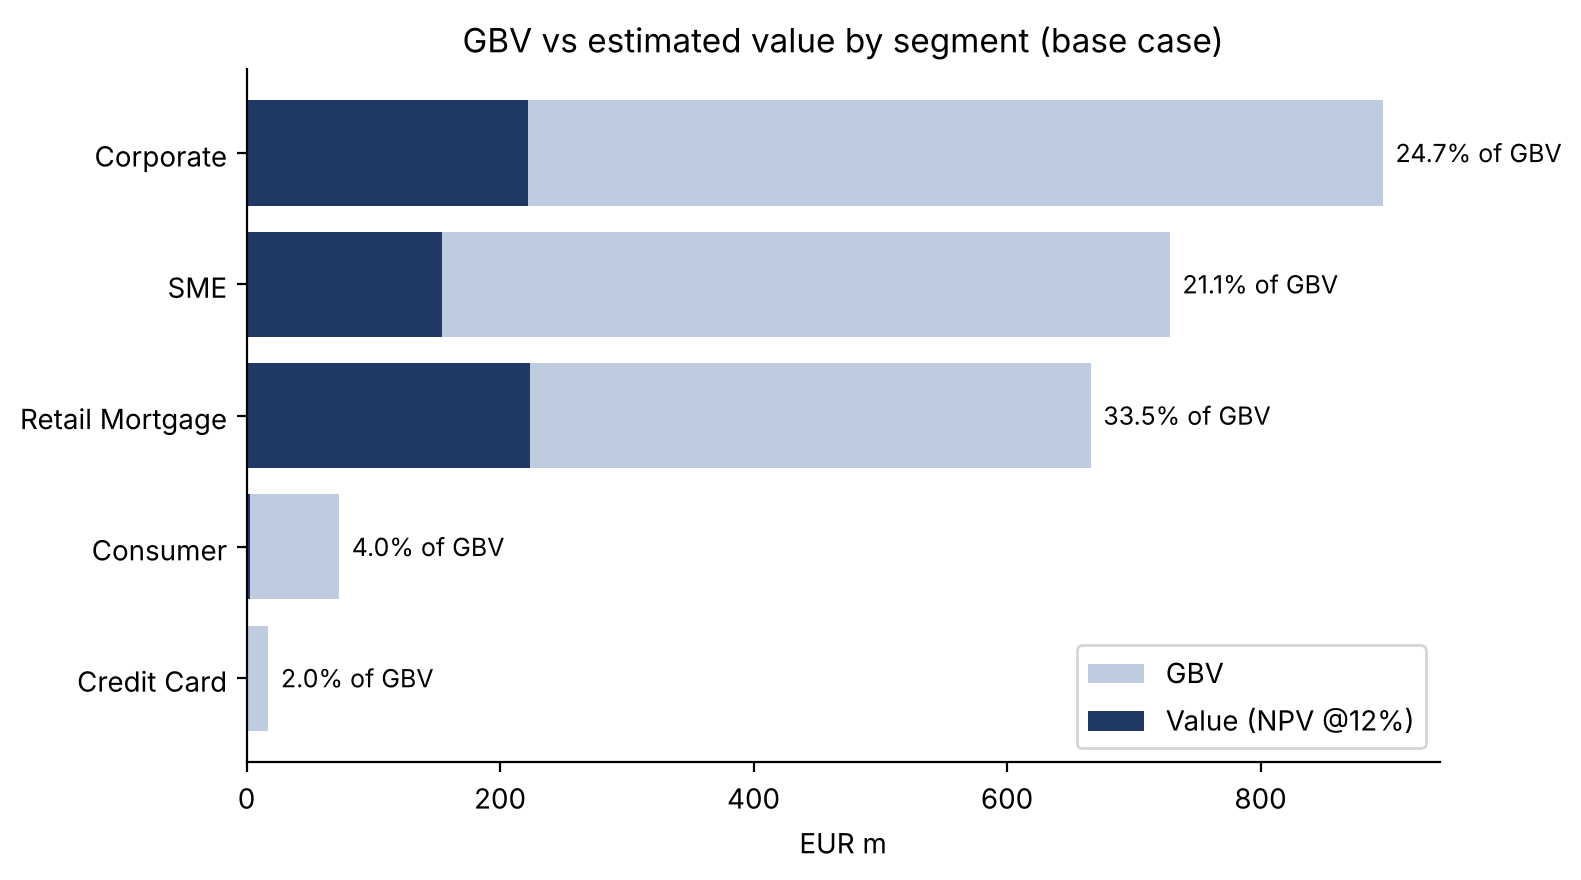

In [15]:
seg = base.groupby('segment')[['gross_book_value', 'npv']].sum() / 1e6
seg = seg.sort_values('gross_book_value')
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(seg.index, seg['gross_book_value'], color='#BFCCE0', label='GBV')
ax.barh(seg.index, seg['npv'], color='#1F3864', label='Value (NPV @12%)')
for i, (g, v) in enumerate(zip(seg['gross_book_value'], seg['npv'])):
    ax.text(g + 10, i, f'{100*v/g:.1f}% of GBV', va='center', fontsize=9)
ax.set_xlabel('EUR m'); ax.set_title('GBV vs estimated value by segment (base case)')
ax.legend(loc='lower right'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('../images/gbv_vs_value_by_segment.png', dpi=150); plt.show()

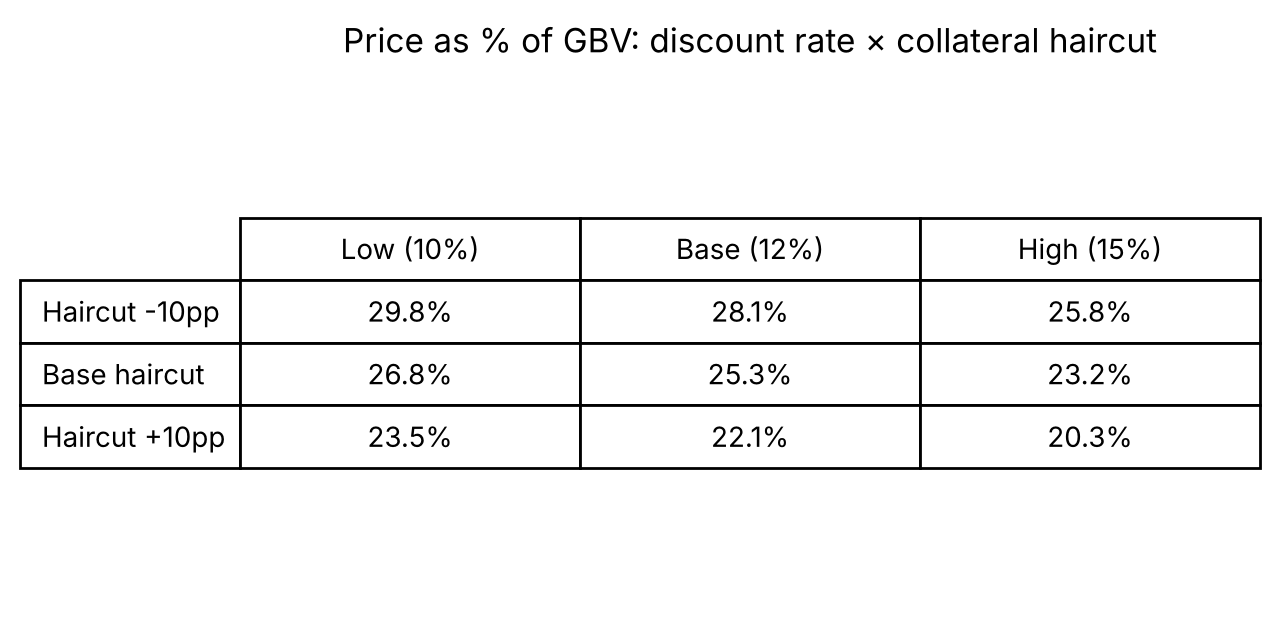

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 3.2)); ax.axis('off')
t = ax.table(cellText=scen.map(lambda v: f'{v:.1f}%').values, rowLabels=scen.index, colLabels=scen.columns,
             loc='center', cellLoc='center')
t.scale(1, 1.8); t.auto_set_font_size(False); t.set_fontsize(10)
ax.set_title('Price as % of GBV: discount rate × collateral haircut', pad=12)
plt.tight_layout(); plt.savefig('../images/scenario_grid.png', dpi=150); plt.show()

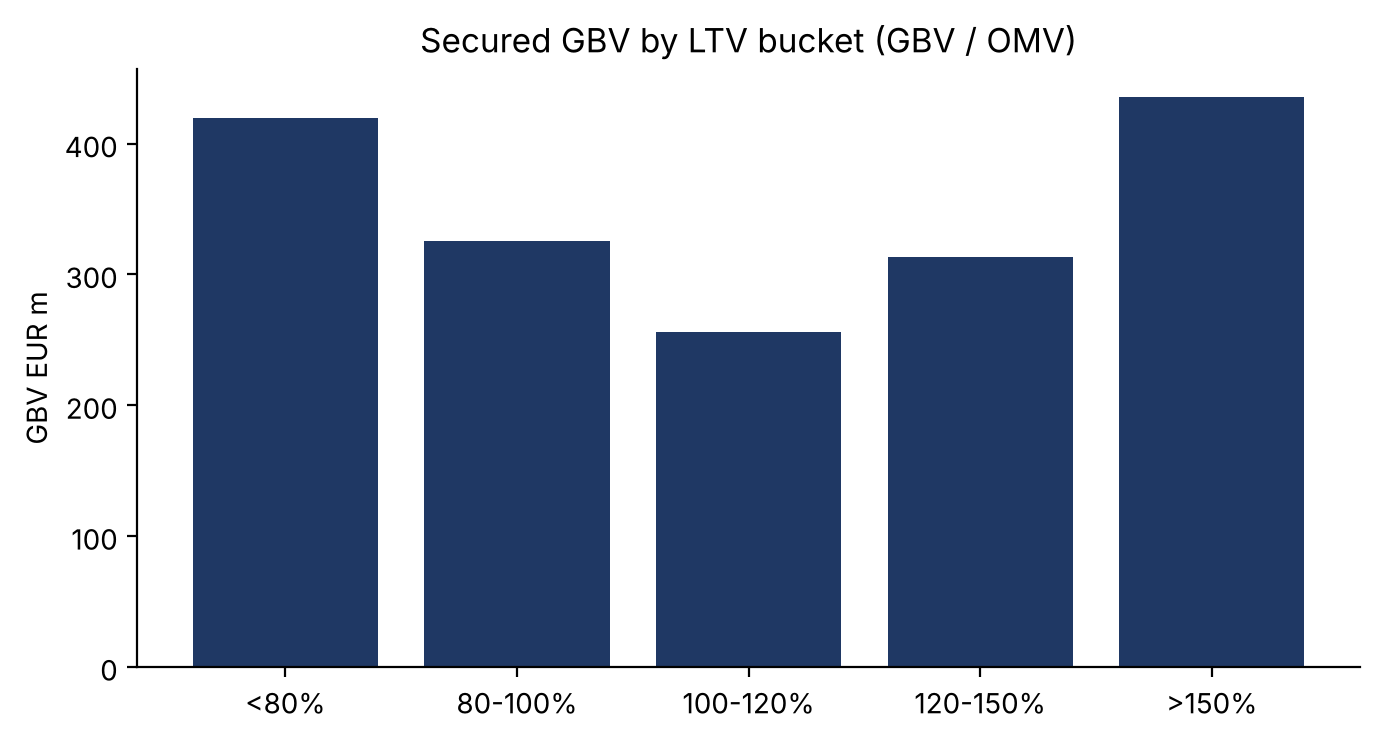

In [17]:
lt = results[3].set_index('ltv_bucket')
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(lt.index.str[3:], lt['gbv_eur_m'], color='#1F3864')
ax.set_ylabel('GBV EUR m'); ax.set_title('Secured GBV by LTV bucket (GBV / OMV)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig('../images/gbv_by_ltv.png', dpi=150); plt.show()

## 7. Export loan-level results (used to cross-check the Excel model)

In [18]:
base[['loan_id', 'segment', 'legal_status', 'gross_book_value', 'collateral_recovery',
      'gross_collections', 'net_collections', 'years', 'npv']].to_csv('../data/loan_level_valuation_base.csv', index=False)
print('NPV EUR m:', round(base['npv'].sum()/1e6, 2))

NPV EUR m: 602.2
